# Classifier decorrelation on real ATLAS Open Data

**Author:** Janus Capellan Aban

This notebook repeats the analysis of `monojet_decorrelation.ipynb` on **real proton–proton collision data and official simulation** from the ATLAS experiment, using the 2025 Open Data for Education and Outreach release (13 TeV, 2015 and 2016, about 36 fb$^{-1}$).

1. Select events with **one lepton, jets and missing transverse energy** ($E_T^{\text{miss}}$), a region rich in top quark pairs ($t\bar t$) and W bosons produced with jets (W + jets).
2. Train a classifier that separates $t\bar t$ (treated here as "signal") from W + jets (treated as "background").
3. Show how cutting on the classifier changes (**sculpts**) the background $E_T^{\text{miss}}$ distribution.
4. Remove the dependence with a **conditional optimal transport (quantile) map**, the same construction as in the monojet notebook.
5. Read the result as a **fairness correction**: background events as negative-outcome cases, $E_T^{\text{miss}}$ groups as protected groups.
6. Apply the classifier and the correction to **real collision data**.

> **Data note.** The events are real ATLAS data and official ATLAS simulation from [CERN Open Data record 93910](https://opendata.cern.ch/record/93910), using the `1LMET30` skim (at least one lepton with $p_T \ge 7$ GeV and $E_T^{\text{miss}} \ge 30$ GeV). This is **not a monojet search**: the release provides no zero-lepton skim, so a monojet selection would need the much larger unskimmed files (see Section 9). The physics question here is a teaching example, not an ATLAS result.

**Before you run.** The files come from CERN over the internet, so you need a working connection. By default the notebook reads a limited number of events per sample (see `MAX_EVENTS_PER_FILE`); start small and increase once everything works. CERN's server limits how many requests one computer may send, so the notebook groups its requests and retries after a pause if it is told to slow down. If that still fails, set `ACCESS = 'download'` in Section 1 to download each file once and read it locally.

**Contents**
1. Setup
2. Samples and file locations
3. Reading and selecting events
4. Training the classifier
5. Background sculpting
6. Decorrelation by conditional optimal transport
7. The fairness reading, with uncertainty
8. Real collision data
9. Towards a monojet selection
10. Limitations and references

## 1. Setup

In [1]:
# Install once (uncomment if needed). aiohttp is required for streaming files over https.
# %pip install atlasopenmagic uproot awkward fsspec aiohttp requests scikit-learn pandas matplotlib

In [2]:
import time
import numpy as np
import pandas as pd
import awkward as ak
import uproot
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve

SEED = 7
rng = np.random.default_rng(SEED)

# ---- What to read ----
RELEASE = '2025e-13tev-beta'            # 2025 Open Data for Education and Outreach (record 93910)
SKIM = '1LMET30'                        # >= 1 lepton (pT >= 7 GeV) and MET >= 30 GeV
SAMPLES = {
    'ttbar': [410470],                  # top quark pairs (used in the official ATLAS Open Data ttbar notebook)
    'wjets': list(range(700338, 700350)),  # Sherpa 2.2.11 W(-> e/mu/tau nu) + jets (from the official Hbb notebook's V+jets list)
}
LUMI_PB = 36000.0                       # integrated luminosity in pb^-1 (about 36 fb^-1)

# ---- How much to read (start small, then increase) ----
MAX_FILES_PER_DSID = 1                  # files per simulated dataset
MAX_EVENTS_PER_FILE = 300_000           # events read per simulated file (None = all)
N_DATA_FILES = 1                        # real-data files to read (the skim has 16 files of roughly 8 GB)
MAX_DATA_EVENTS = 2_000_000             # events read from each data file (None = all)
ACCESS = 'stream'                       # 'stream': read only the needed parts of each file over the internet
                                        # 'download': download each file once (resumable), then read it locally.
                                        # Switch to 'download' if CERN keeps answering 'Too Many Requests' (HTTP 429).
CACHE_DIR = 'atlas_opendata_cache'      # where downloaded files are kept in 'download' mode

# Optional: read files you have already downloaded instead of streaming.
# Example: LOCAL_FILES = {'ttbar': ['/path/410470.....1LMET30.root'], 'wjets': [...], 'data': [...]}
LOCAL_FILES = None

# ---- Analysis settings ----
N_BINS = 10                             # MET groups used to evaluate fairness
K_NEIGHBOURS = 400                      # calibration events used per conditional distribution
SIG_EFF = 0.5                           # cut keeps this fraction of ttbar
ALPHA = 0.05

COL = {'ttbar': '#eb6834', 'wjets': '#1baf7a', 'orig': '#eb6834', 'dc': '#2a78d6', 'data': '#1f1e1c'}
LABEL = {'ttbar': r'$t\bar{t}$ (treated as signal)', 'wjets': 'W + jets (treated as background)'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
                     'axes.edgecolor': '#8a8983', 'axes.titleweight': 'bold', 'lines.linewidth': 2})

## 2. Samples and file locations

`atlasopenmagic` is the official ATLAS helper package. It returns the location of every file in a release. The cell below also prints each simulated dataset's short name, so you can check that the dataset numbers are the processes we expect.

In [3]:
def get_file_lists():
    if LOCAL_FILES is not None:
        print('Using local files.')
        return {k: list(v) for k, v in LOCAL_FILES.items()}
    import atlasopenmagic as atom
    atom.set_release(RELEASE)
    files = {}
    for name, dids in SAMPLES.items():
        files[name] = []
        for did in dids:
            try:
                short = atom.get_metadata(str(did), 'physics_short')
                urls = atom.get_urls(str(did), skim=SKIM, protocol='https', cache=False)
                files[name] += urls[:MAX_FILES_PER_DSID]
                print(f'{name:6s} {did}  {short}  ({len(urls)} file(s) in {SKIM})')
            except Exception as err:            # a dataset may be missing from this release or skim
                print(f'{name:6s} {did}  skipped: {err}')
    files['data'] = atom.get_urls('data', skim=SKIM, protocol='https', cache=False)[:N_DATA_FILES]
    print(f'data   {len(files["data"])} file(s)')
    return files

FILES = get_file_lists()

Fetching metadata for release: 2025e-13tev-beta...
Fetching datasets: 100%|██████████| 374/374 [00:00<00:00, 412.29datasets/s]
✓ Successfully cached 374 datasets.
Active release: 2025e-13tev-beta. (Datasets path: REMOTE)


ttbar  410470  PhPy8EG_A14_ttbar_hdamp258p75_nonallhad  (1 file(s) in 1LMET30)
wjets  700338  Sh_2211_Wenu_maxHTpTV2_BFilter  (1 file(s) in 1LMET30)
wjets  700339  Sh_2211_Wenu_maxHTpTV2_CFilterBVeto  (1 file(s) in 1LMET30)
wjets  700340  Sh_2211_Wenu_maxHTpTV2_CVetoBVeto  (1 file(s) in 1LMET30)
wjets  700341  Sh_2211_Wmunu_maxHTpTV2_BFilter  (1 file(s) in 1LMET30)
wjets  700342  Sh_2211_Wmunu_maxHTpTV2_CFilterBVeto  (1 file(s) in 1LMET30)
wjets  700343  Sh_2211_Wmunu_maxHTpTV2_CVetoBVeto  (1 file(s) in 1LMET30)
wjets  700344  Sh_2211_Wtaunu_L_maxHTpTV2_BFilter  (1 file(s) in 1LMET30)
wjets  700345  Sh_2211_Wtaunu_L_maxHTpTV2_CFilterBVeto  (1 file(s) in 1LMET30)
wjets  700346  Sh_2211_Wtaunu_L_maxHTpTV2_CVetoBVeto  (1 file(s) in 1LMET30)
wjets  700347  Sh_2211_Wtaunu_H_maxHTpTV2_BFilter  (1 file(s) in 1LMET30)
wjets  700348  Sh_2211_Wtaunu_H_maxHTpTV2_CFilterBVeto  (1 file(s) in 1LMET30)
wjets  700349  Sh_2211_Wtaunu_H_maxHTpTV2_CVetoBVeto  (1 file(s) in 1LMET30)
data   1 file(s)


## 3. Reading and selecting events

Only the branches the analysis needs are read. The selection follows the official ATLAS Open Data $t\bar t$ example, but stops before the b-tagging requirement so that both processes remain:

| Requirement | Value |
|---|---|
| Single-electron or single-muon trigger | fired |
| Leptons | exactly one, $p_T \ge 30$ GeV, matched to the trigger, medium identification, loose isolation |
| Jets | at least two with $p_T \ge 30$ GeV, $|\eta| < 2.5$, passing the pile-up (JVT) requirement |
| $E_T^{\text{miss}}$ | $\ge 30$ GeV |
| W transverse mass $m_T$ | $\ge 30$ GeV |

Simulated events are weighted to the data luminosity with the standard ATLAS Open Data weight (cross section, generator weight, scale factors).

**Network safeguards.** Requests are grouped into fewer, larger ones, at most 8 run at once, and any request refused with "Too Many Requests" (HTTP 429), a server error or a dropped connection is retried after a growing pause. Messages about waiting are normal. If this cell fails, every later cell fails too, because nothing was read; fix the problem here, then use **Kernel, Restart and Run All**.

In [4]:
EVENT_BRANCHES = ['trigE', 'trigM', 'lep_n', 'lep_pt', 'lep_eta', 'lep_phi', 'lep_type', 'lep_isTrigMatched',
                  'lep_isMediumID', 'lep_isLooseIso', 'met', 'met_phi',
                  'jet_pt', 'jet_eta', 'jet_phi', 'jet_jvt', 'jet_btag_quantile']
WEIGHT_BRANCHES = ['mcWeight', 'sum_of_weights', 'xsec', 'kfac', 'filteff', 'ScaleFactor_PILEUP', 'ScaleFactor_FTAG',
                   'ScaleFactor_ELE', 'ScaleFactor_MUON', 'ScaleFactor_ElTRIGGER', 'ScaleFactor_MuTRIGGER']

def select(ev, is_mc):
    """Apply the event selection to an awkward array and return a flat pandas DataFrame (energies in GeV)."""
    ev = ev[((ev.trigE == 1) | (ev.trigM == 1)) & (ev.lep_n == 1)]
    good_lep = (ev.lep_pt >= 30) & (ev.lep_isTrigMatched == 1) & (ev.lep_isMediumID == 1) & (ev.lep_isLooseIso == 1)
    ev = ev[ak.sum(good_lep, axis=1) == 1]
    good_jet = (ev.jet_pt >= 30) & (abs(ev.jet_eta) < 2.5) & (ev.jet_jvt == 1)
    njet = ak.sum(good_jet, axis=1)
    lep_pt, lep_phi = ak.firsts(ev.lep_pt), ak.firsts(ev.lep_phi)
    mt = np.sqrt(np.maximum(2 * lep_pt * ev.met * (1 - np.cos(lep_phi - ev.met_phi)), 0))
    keep = (njet >= 2) & (ev.met >= 30) & (mt >= 30)
    ev, good_jet, njet, mt = ev[keep], good_jet[keep], njet[keep], mt[keep]
    jpt = ak.sort(ev.jet_pt[good_jet], axis=1, ascending=False)
    jpt = ak.fill_none(ak.pad_none(jpt, 2), 0.0)
    out = pd.DataFrame({
        'met': ak.to_numpy(ev.met),
        'mt': ak.to_numpy(mt),
        'lep_pt': ak.to_numpy(ak.firsts(ev.lep_pt)),
        'lep_abs_eta': ak.to_numpy(abs(ak.firsts(ev.lep_eta))),
        'dphi_lep_met': ak.to_numpy(abs((ak.firsts(ev.lep_phi) - ev.met_phi + np.pi) % (2 * np.pi) - np.pi)),
        'n_jets': ak.to_numpy(njet),
        'n_bjets': ak.to_numpy(ak.sum(good_jet & (ev.jet_btag_quantile >= 4), axis=1)),
        'jet1_pt': ak.to_numpy(jpt[:, 0]),
        'jet2_pt': ak.to_numpy(jpt[:, 1]),
        'ht': ak.to_numpy(ak.sum(ev.jet_pt[good_jet], axis=1)),
    })
    if is_mc:
        w = (ev.ScaleFactor_PILEUP * ev.ScaleFactor_FTAG * ev.mcWeight / ev.sum_of_weights
             * LUMI_PB * ev.xsec * ev.kfac * ev.filteff)
        is_el = ak.firsts(ev.lep_type) == 11
        w = ak.where(is_el, w * ev.ScaleFactor_ELE * ev.ScaleFactor_ElTRIGGER, w * ev.ScaleFactor_MUON * ev.ScaleFactor_MuTRIGGER)
        out['weight'] = ak.to_numpy(w).astype(float)
    else:
        out['weight'] = 1.0
    return out

import os, requests, uproot.source.coalesce

# Fewer, larger requests: CERN's server rate-limits clients that send many small requests (HTTP 429).
COALESCE = uproot.source.coalesce.CoalesceConfig(max_range_gap=2 * 1024 * 1024, max_request_ranges=4096,
                                                 max_request_bytes=64 * 1024 * 1024)
STEP_ENTRIES = 200_000                  # events per chunk (a fixed number avoids extra small requests)
MAX_ATTEMPTS = 8                        # retries after a network error
RETRY_BASE_SECONDS = 2                  # first pause before retrying one request (doubles each time, with jitter)

import asyncio, random, aiohttp, fsspec
from fsspec.implementations.http import HTTPFileSystem

class PoliteHTTPFileSystem(HTTPFileSystem):
    """HTTP file system that retries a request after 'Too Many Requests' (429), server errors or dropped connections."""
    async def _retry(self, method, *args, **kwargs):
        for attempt in range(MAX_ATTEMPTS):
            try:
                return await method(*args, **kwargs)
            except aiohttp.ClientResponseError as err:
                if err.status not in (429, 500, 502, 503, 504) or attempt == MAX_ATTEMPTS - 1:
                    raise
            except (aiohttp.ClientError, asyncio.TimeoutError):
                if attempt == MAX_ATTEMPTS - 1:
                    raise
            await asyncio.sleep(min(120, RETRY_BASE_SECONDS * 2 ** attempt) * (1 + random.random()))

    async def _cat_file(self, url, start=None, end=None, **kwargs):
        return await self._retry(super()._cat_file, url, start=start, end=end, **kwargs)

    async def _info(self, url, **kwargs):
        return await self._retry(super()._info, url, **kwargs)

fsspec.register_implementation('https', PoliteHTTPFileSystem, clobber=True)
fsspec.register_implementation('http', PoliteHTTPFileSystem, clobber=True)
fsspec.config.conf['gather_batch_size'] = 8   # at most 8 simultaneous requests

def _wait(attempt, err):
    pause = min(300, 15 * 2 ** attempt)
    print(f'    network problem ({type(err).__name__}: {str(err)[:80]}); waiting {pause} s, then retrying')
    time.sleep(pause)

def download(url):
    """Download a file once into CACHE_DIR, resuming after interruptions. Returns the local path."""
    os.makedirs(CACHE_DIR, exist_ok=True)
    dest = os.path.join(CACHE_DIR, url.split('/')[-1])
    if os.path.exists(dest):
        return dest
    tmp = dest + '.part'
    for attempt in range(MAX_ATTEMPTS):
        try:
            pos = os.path.getsize(tmp) if os.path.exists(tmp) else 0
            headers = {'Range': f'bytes={pos}-'} if pos else {}
            with requests.get(url, headers=headers, stream=True, timeout=120) as r:
                if r.status_code == 429:
                    raise RuntimeError('HTTP 429 Too Many Requests')
                r.raise_for_status()
                if pos and r.status_code != 206:          # server ignored the resume request: start again
                    pos = 0
                total = pos + int(r.headers.get('Content-Length', 0))
                print(f'    downloading {dest} ({total / 1e9:.2f} GB)')
                with open(tmp, 'ab' if pos else 'wb') as f:
                    for block in r.iter_content(chunk_size=8 * 1024 * 1024):
                        f.write(block)
            os.replace(tmp, dest)
            return dest
        except Exception as err:
            if attempt == MAX_ATTEMPTS - 1:
                raise
            _wait(attempt, err)

def read_file(url, is_mc, max_events):
    """Read and select one file, resuming from the last completed chunk after a network error."""
    remote = '://' in url
    if remote and ACCESS == 'download':
        url, remote = download(url), False
    opts = {'coalesce_config': COALESCE, 'timeout': 120} if remote else {}
    branches = EVENT_BRANCHES + (WEIGHT_BRANCHES if is_mc else [])
    frames, start, stop = [], 0, None
    for attempt in range(MAX_ATTEMPTS):
        try:
            with uproot.open({url: 'analysis'}, **opts) as tree:
                if stop is None:
                    stop = tree.num_entries if max_events is None else min(tree.num_entries, max_events)
                for chunk in tree.iterate(branches, entry_start=start, entry_stop=stop,
                                          step_size=STEP_ENTRIES, library='ak'):
                    frames.append(select(chunk, is_mc))
                    start += len(chunk)
            return frames, stop
        except Exception as err:
            if attempt == MAX_ATTEMPTS - 1 or not remote:
                raise
            _wait(attempt, err)

def read_sample(urls, is_mc, max_events):
    frames, n_read = [], 0
    for url in urls:
        t0 = time.time()
        f, n = read_file(url, is_mc, max_events)
        frames += f; n_read += n
        print(f'  read {n:>10,} events in {time.time() - t0:6.1f} s from {url.split("/")[-1]}')
        time.sleep(1)                   # be gentle with the server between files
    df = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    print(f'  {len(df):,} of {n_read:,} events pass the selection')
    return df

t_all = time.time()
parts = []
for name in ('ttbar', 'wjets'):
    print(f'Reading {name}')
    d = read_sample(FILES[name], True, MAX_EVENTS_PER_FILE)
    d['process'] = name
    parts.append(d)
mc = pd.concat(parts, ignore_index=True)
if mc.empty or mc.process.nunique() < 2 or (mc.process == 'ttbar').sum() < 1000 or (mc.process == 'wjets').sum() < 1000:
    raise RuntimeError('Too few simulated events were read. Check the messages above, then increase MAX_EVENTS_PER_FILE.')
print('Reading data')
data = read_sample(FILES['data'], False, MAX_DATA_EVENTS)
print(f'Total reading time: {(time.time() - t_all) / 60:.1f} min')

mc['y'] = (mc.process == 'ttbar').astype(int)
mc['w_abs'] = mc.weight.abs()           # absolute weights for training and efficiencies (see Section 10)
FEATURES = ['met', 'mt', 'lep_pt', 'lep_abs_eta', 'dphi_lep_met', 'n_jets', 'n_bjets', 'jet1_pt', 'jet2_pt', 'ht']
summary = mc.groupby('process').agg(events=('met', 'size'), weighted_yield=('weight', 'sum'),
                                    negative_weight_fraction=('weight', lambda w: float(np.mean(w < 0))))
summary.loc['data (selected)'] = [len(data), float(len(data)), 0.0]
summary.round(3)

Reading ttbar
  read    300,000 events in   92.2 s from ODEO_FEB2025_v0_1LMET30_mc_410470.PhPy8EG_A14_ttbar_hdamp258p75_nonallhad.1LMET30.root
  86,364 of 300,000 events pass the selection
Reading wjets
  read    300,000 events in   34.9 s from ODEO_FEB2025_v0_1LMET30_mc_700338.Sh_2211_Wenu_maxHTpTV2_BFilter.1LMET30.root
  read    300,000 events in  108.3 s from ODEO_FEB2025_v0_1LMET30_mc_700339.Sh_2211_Wenu_maxHTpTV2_CFilterBVeto.1LMET30.root
  read    300,000 events in  107.6 s from ODEO_FEB2025_v0_1LMET30_mc_700340.Sh_2211_Wenu_maxHTpTV2_CVetoBVeto.1LMET30.root
  read    300,000 events in   46.2 s from ODEO_FEB2025_v0_1LMET30_mc_700341.Sh_2211_Wmunu_maxHTpTV2_BFilter.1LMET30.root
  read    300,000 events in   76.6 s from ODEO_FEB2025_v0_1LMET30_mc_700342.Sh_2211_Wmunu_maxHTpTV2_CFilterBVeto.1LMET30.root
  read    300,000 events in  101.2 s from ODEO_FEB2025_v0_1LMET30_mc_700343.Sh_2211_Wmunu_maxHTpTV2_CVetoBVeto.1LMET30.root
  read    300,000 events in   31.2 s from ODEO_FEB2025_v0_

,events,weighted_yield,negative_weight_fraction
process,,,
ttbar,86364.0,40523.805,0.004
wjets,454557.0,54205.085,0.145
data (selected),17115.0,17115.000,0.000


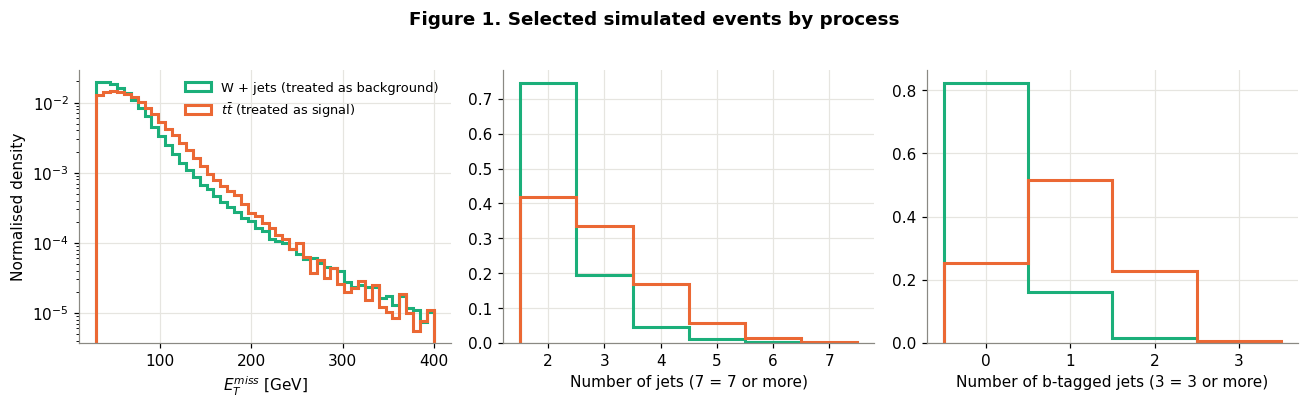

In [5]:
def wquantile(x, w, q):
    """Weighted quantile(s) of x."""
    o = np.argsort(x); x, w = np.asarray(x)[o], np.asarray(w)[o]
    c = np.cumsum(w); c = c / c[-1]
    return np.interp(q, c, x)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for p in ('wjets', 'ttbar'):
    d = mc[mc.process == p]
    axes[0].hist(d.met, bins=np.linspace(30, 400, 50), weights=d.w_abs, density=True, histtype='step', lw=2, color=COL[p], label=LABEL[p])
    axes[1].hist(d.n_jets.clip(upper=7), bins=np.arange(1.5, 8.5), weights=d.w_abs, density=True, histtype='step', lw=2, color=COL[p])
    axes[2].hist(d.n_bjets.clip(upper=3), bins=np.arange(-0.5, 4.5), weights=d.w_abs, density=True, histtype='step', lw=2, color=COL[p])
axes[0].set_yscale('log'); axes[0].set_xlabel('$E_T^{miss}$ [GeV]'); axes[0].set_ylabel('Normalised density')
axes[1].set_xlabel('Number of jets (7 = 7 or more)'); axes[2].set_xlabel('Number of b-tagged jets (3 = 3 or more)')
axes[0].legend(frameon=False, fontsize=8.5)
fig.suptitle('Figure 1. Selected simulated events by process', fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()

## 4. Training the classifier

Simulated events are split into **training** (50%), **calibration** (25%, used only to fit the decorrelation map) and **test** (25%, used for every result). The two classes are given equal total weight in training. The classifier sees all features, including $E_T^{\text{miss}}$.

In [6]:
idx = rng.permutation(len(mc))
tr, ca, te = np.split(idx, [int(0.5 * len(mc)), int(0.75 * len(mc))])
mc['split'] = 'train'; mc.loc[ca, 'split'] = 'calib'; mc.loc[te, 'split'] = 'test'

train = mc.loc[tr]
cls_w = train.w_abs / train.groupby('y').w_abs.transform('sum')    # balance the two classes
t0 = time.time()
clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=0)
clf.fit(train[FEATURES], train.y, sample_weight=cls_w)
print(f'Trained on {len(train):,} events in {time.time() - t0:.1f} s')

for part in (ca, te):
    # tiny random jitter breaks ties so the quantile transform below is well defined
    mc.loc[part, 'score'] = clf.predict_proba(mc.loc[part, FEATURES])[:, 1] + 1e-9 * rng.uniform(size=len(part))
data['score'] = clf.predict_proba(data[FEATURES])[:, 1] + 1e-9 * rng.uniform(size=len(data))

test = mc[mc.split == 'test']; calib = mc[mc.split == 'calib']
print(f"Test AUC (weighted): {roc_auc_score(test.y, test.score, sample_weight=test.w_abs):.3f}")

Trained on 270,460 events in 3.5 s
Test AUC (weighted): 0.876


## 5. Background sculpting

We cut at the threshold that keeps 50% of the (weighted) $t\bar t$ events and compare the W + jets $E_T^{\text{miss}}$ distribution before and after the cut. A flat ratio means no sculpting; a ratio that rises or falls with $E_T^{\text{miss}}$ means the cut has reshaped the background.

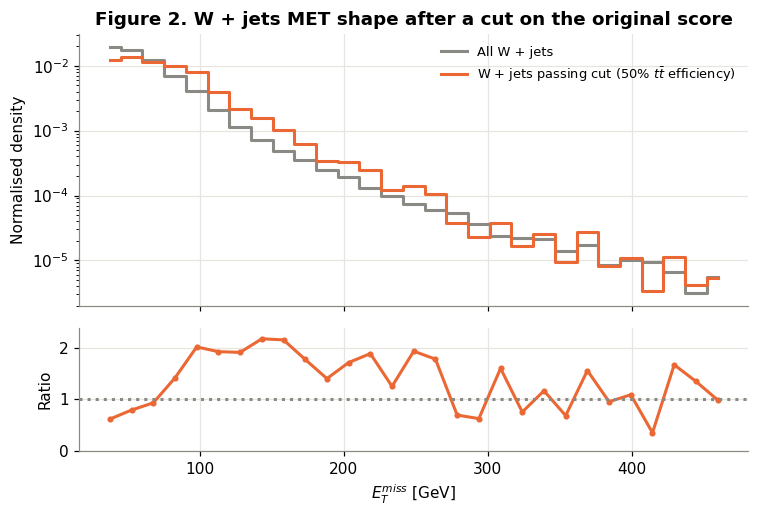

W + jets efficiency per MET group (low to high): [0.026 0.027 0.031 0.034 0.039 0.039 0.059 0.076 0.083 0.073]


In [7]:
bkg_cal = calib[calib.y == 0]
edges = np.quantile(bkg_cal.met, np.linspace(0, 1, N_BINS + 1))
edges[0], edges[-1] = 0.0, np.inf
MET_MAX = float(np.quantile(bkg_cal.met, 0.995))

def met_bin(met):
    return np.clip(np.searchsorted(edges, met, side='right') - 1, 0, N_BINS - 1)

def bin_efficiency(bkg, score_col, thr):
    """Weighted background efficiency (false-positive rate) in each MET group at threshold thr."""
    k = met_bin(bkg.met.values); s = bkg[score_col].values; w = bkg.w_abs.values
    return np.array([np.sum(w[(k == j) & (s > thr)]) / np.sum(w[k == j]) for j in range(N_BINS)])

def sculpt_plot(score_col, title):
    bkg, sig = test[test.y == 0], test[test.y == 1]
    thr = wquantile(sig[score_col], sig.w_abs, 1 - SIG_EFF)
    bins = np.linspace(30, MET_MAX, 30)
    h_all, _ = np.histogram(bkg.met, bins=bins, weights=bkg.w_abs, density=True)
    cut = bkg[score_col] > thr
    h_cut, _ = np.histogram(bkg.met[cut], bins=bins, weights=bkg.w_abs[cut], density=True)
    ctr = 0.5 * (bins[1:] + bins[:-1])
    c = COL['orig'] if score_col == 'score' else COL['dc']
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(7, 4.8), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})
    a1.step(ctr, h_all, where='mid', color='#8a8983', label='All W + jets')
    a1.step(ctr, h_cut, where='mid', color=c, label=f'W + jets passing cut ({100 * SIG_EFF:.0f}% $t\\bar{{t}}$ efficiency)')
    a1.set_yscale('log'); a1.set_ylabel('Normalised density'); a1.legend(frameon=False, fontsize=8.5); a1.set_title(title)
    with np.errstate(divide='ignore', invalid='ignore'):
        ratio = np.where(h_all > 0, h_cut / h_all, np.nan)
    a2.plot(ctr, ratio, color=c, marker='o', ms=3)
    a2.axhline(1, color='#8a8983', ls=':'); a2.set_ylabel('Ratio'); a2.set_xlabel('$E_T^{miss}$ [GeV]')
    a2.set_ylim(0, max(2, np.nanmax(ratio) * 1.1))
    plt.tight_layout(); plt.show()
    return thr

thr_orig = sculpt_plot('score', 'Figure 2. W + jets MET shape after a cut on the original score')
eff_orig = bin_efficiency(test[test.y == 0], 'score', thr_orig)
print('W + jets efficiency per MET group (low to high):', np.round(eff_orig, 3))

## 6. Decorrelation by conditional optimal transport

As in the monojet notebook, each score is replaced by its percentile among the $k$ calibration **background** events closest in $E_T^{\text{miss}}$:

$$\tilde s = \hat F_{E_T^{\text{miss}}}(s).$$

Here the percentile is **weighted** by the absolute event weights, so the map reflects the physical mixture of W + jets subsamples. Background $\tilde s$ is then approximately uniform at every $E_T^{\text{miss}}$, so any cut keeps about the same fraction of background everywhere. This is a simple, continuous version of the classifier decorrelation via optimal transport studied by Chakravarti et al. (2024) and Algren et al. (2024).

In [8]:
order = np.argsort(bkg_cal.met.values)
CAL_MET, CAL_SCORE, CAL_W = bkg_cal.met.values[order], bkg_cal.score.values[order], bkg_cal.w_abs.values[order]
K = min(K_NEIGHBOURS, len(CAL_MET))

def decorrelate(met, score, k=K):
    """score -> weighted rank among the k calibration background events nearest in MET."""
    n = len(CAL_MET)
    start = np.clip(np.searchsorted(CAL_MET, met) - k // 2, 0, n - k)
    out = np.empty(len(score))
    for i in range(len(score)):
        s, w = CAL_SCORE[start[i]:start[i] + k], CAL_W[start[i]:start[i] + k]
        out[i] = np.sum(w[s <= score[i]]) / np.sum(w)
    return out

t0 = time.time()
mc.loc[te, 'score_dc'] = decorrelate(mc.loc[te, 'met'].values, mc.loc[te, 'score'].values)
data['score_dc'] = decorrelate(data.met.values, data.score.values)
test = mc[mc.split == 'test']
print(f'Decorrelated {len(te) + len(data):,} events in {time.time() - t0:.1f} s using {len(CAL_MET):,} calibration background events')

Decorrelated 152,346 events in 0.9 s using 113,593 calibration background events


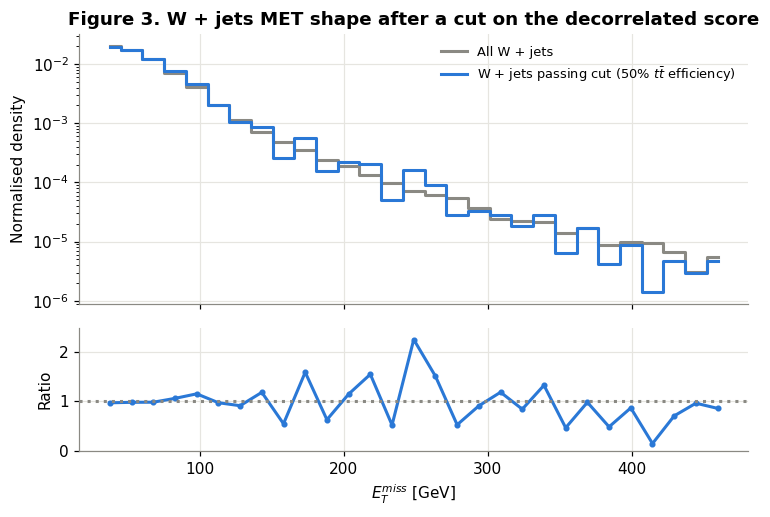

W + jets efficiency per MET group (low to high): [0.05  0.047 0.052 0.045 0.047 0.05  0.055 0.051 0.049 0.049]


In [9]:
thr_dc = sculpt_plot('score_dc', 'Figure 3. W + jets MET shape after a cut on the decorrelated score')
eff_dc = bin_efficiency(test[test.y == 0], 'score_dc', thr_dc)
print('W + jets efficiency per MET group (low to high):', np.round(eff_dc, 3))

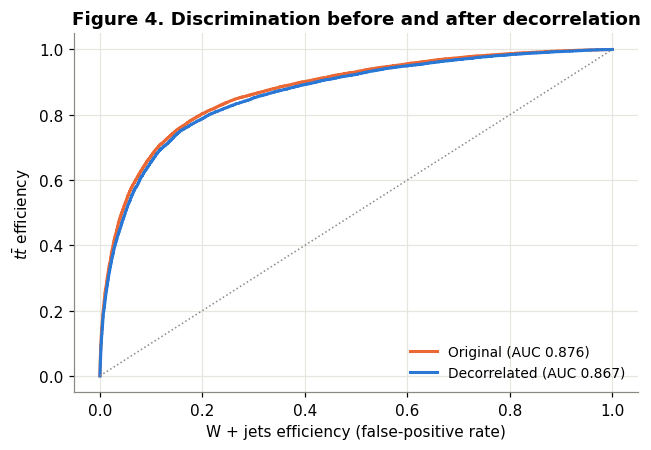

In [10]:
fig, ax = plt.subplots(figsize=(6, 4.2))
for col, name, c in (('score', 'Original', COL['orig']), ('score_dc', 'Decorrelated', COL['dc'])):
    fpr, tpr, _ = roc_curve(test.y, test[col], sample_weight=test.w_abs)
    ax.plot(fpr, tpr, color=c, label=f'{name} (AUC {roc_auc_score(test.y, test[col], sample_weight=test.w_abs):.3f})')
ax.plot([0, 1], [0, 1], color='#8a8983', ls=':', lw=1)
ax.set_xlabel('W + jets efficiency (false-positive rate)'); ax.set_ylabel(r'$t\bar{t}$ efficiency')
ax.set_title('Figure 4. Discrimination before and after decorrelation'); ax.legend(frameon=False, fontsize=9, loc='lower right')
plt.tight_layout(); plt.show()

## 7. The fairness reading, with uncertainty

Read W + jets events as **negative-outcome cases** and $E_T^{\text{miss}}$ groups as **protected groups**. The W + jets efficiency in each group is then that group's **false-positive rate**.

| Particle physics | Fairness |
|---|---|
| Background (W + jets) events | Negative-outcome cases |
| $E_T^{\text{miss}}$ group | Protected group |
| Background efficiency in a group | Group false-positive rate |
| Sculpting of the background shape | Unequal false-positive rates |

We measure the largest gap between any group's false-positive rate and the pooled rate, over **all** thresholds, and compare it with a rough finite-sample reference: a Dvoretzky–Kiefer–Wolfowitz half-width per group, using each group's effective number of weighted events, plus the calibration window of $k$ events.

In [11]:
def max_gap(bkg, score_col, n_thr=201):
    k = met_bin(bkg.met.values); s = bkg[score_col].values; w = bkg.w_abs.values
    thr = np.quantile(s, np.linspace(0.005, 0.995, n_thr))
    pass_ = s[:, None] > thr[None, :]
    pooled = (w[:, None] * pass_).sum(0) / w.sum()
    gaps = []
    for j in range(N_BINS):
        m = k == j
        gaps.append(np.max(np.abs((w[m, None] * pass_[m]).sum(0) / w[m].sum() - pooled)))
    n_eff = np.array([w[k == j].sum() ** 2 / (w[k == j] ** 2).sum() for j in range(N_BINS)])
    return max(gaps), n_eff

bkg_test = test[test.y == 0]
gap_orig, n_eff = max_gap(bkg_test, 'score')
gap_dc, _ = max_gap(bkg_test, 'score_dc')
noise = np.max(np.sqrt(np.log(2 * N_BINS / ALPHA) / (2 * n_eff))) + np.sqrt(np.log(2 * N_BINS / ALPHA) / (2 * K))
results = pd.DataFrame({'Largest false-positive-rate gap (any group, any threshold)': [gap_orig, gap_dc],
                        'Finite-sample reference (95%)': [noise, noise],
                        'Test AUC': [roc_auc_score(test.y, test.score, sample_weight=test.w_abs),
                                     roc_auc_score(test.y, test.score_dc, sample_weight=test.w_abs)]},
                       index=['Original score', 'Decorrelated score']).round(3)
results

,"Largest false-positive-rate gap (any group, any threshold)",Finite-sample reference (95%),Test AUC
Original score,0.289,0.135,0.876
Decorrelated score,0.042,0.135,0.867


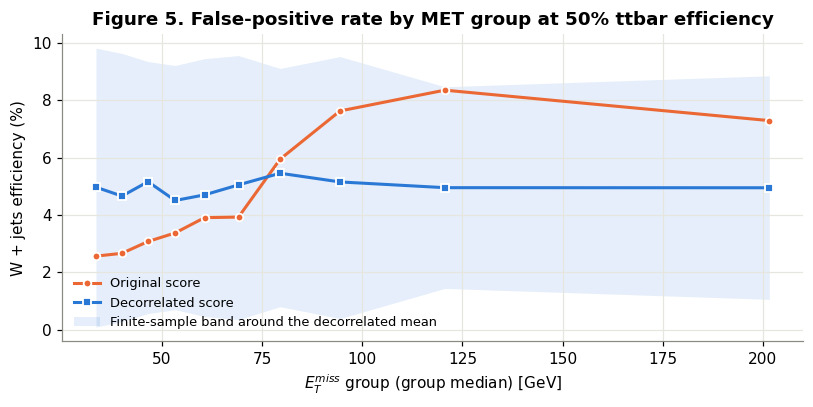

In [12]:
ctr = np.array([np.median(bkg_test.met.values[met_bin(bkg_test.met.values) == j]) for j in range(N_BINS)])
band = np.sqrt(np.log(2 * N_BINS / ALPHA) / (2 * n_eff))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(ctr, 100 * eff_orig, color=COL['orig'], marker='o', ms=5, mec='white', mew=1.2, label='Original score')
ax.plot(ctr, 100 * eff_dc, color=COL['dc'], marker='s', ms=5, mec='white', mew=1.2, label='Decorrelated score')
ax.fill_between(ctr, 100 * (eff_dc.mean() - band), 100 * (eff_dc.mean() + band), color=COL['dc'], alpha=0.12, lw=0,
                label='Finite-sample band around the decorrelated mean')
ax.set_xlabel('$E_T^{miss}$ group (group median) [GeV]'); ax.set_ylabel('W + jets efficiency (%)')
ax.set_title(f'Figure 5. False-positive rate by MET group at {100 * SIG_EFF:.0f}% ttbar efficiency')
ax.legend(frameon=False, fontsize=8.5, loc='best')
plt.tight_layout(); plt.show()

**How to read Figure 5 and the table.** If decorrelation works, the decorrelated curve should be roughly flat and its largest gap should be comparable to the finite-sample reference, while the original curve may vary strongly with $E_T^{\text{miss}}$. Saying *how* small the true gap is, with a guarantee that holds even though the map was fitted on data, is the uncertainty-quantification question at the heart of the fairness project.

## 8. Real collision data

The classifier and the decorrelation map were built on simulation only. We now apply both, unchanged, to real ATLAS collision data that pass the same selection.

Two checks:
- **Score shapes.** Real data compared with the simulated $t\bar t$ + W + jets mixture. Other processes present in data (single top, Z + jets, dibosons, multijet events with a fake lepton) are **not** simulated here, so only shapes are compared and some disagreement is expected.
- **Effect of the cut on the $E_T^{\text{miss}}$ spectrum of real data.** Data contain both $t\bar t$ and W + jets, so a cut always changes the spectrum somewhat; the question is how differently the original and decorrelated cuts change it.

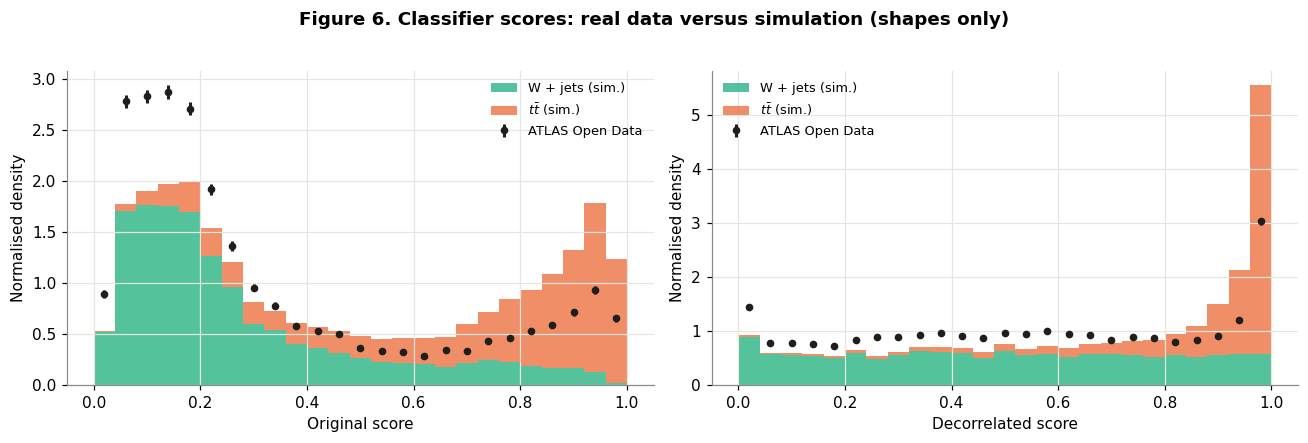

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
for ax, col, ttl in ((axes[0], 'score', 'Original score'), (axes[1], 'score_dc', 'Decorrelated score')):
    bins = np.linspace(0, 1, 26)
    mix = test
    ax.hist([mix[col][mix.y == 0], mix[col][mix.y == 1]], bins=bins, weights=[mix.weight[mix.y == 0], mix.weight[mix.y == 1]],
            stacked=True, density=True, color=[COL['wjets'], COL['ttbar']], alpha=0.75, label=['W + jets (sim.)', r'$t\bar{t}$ (sim.)'])
    h, _ = np.histogram(data[col], bins=bins, density=True)
    n, _ = np.histogram(data[col], bins=bins)
    width = bins[1] - bins[0]
    err = np.sqrt(n) / max(len(data), 1) / width
    ax.errorbar(0.5 * (bins[1:] + bins[:-1]), h, yerr=err, fmt='o', color=COL['data'], ms=4, label='ATLAS Open Data')
    ax.set_xlabel(ttl); ax.set_ylabel('Normalised density'); ax.legend(frameon=False, fontsize=8.5)
fig.suptitle('Figure 6. Classifier scores: real data versus simulation (shapes only)', fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()

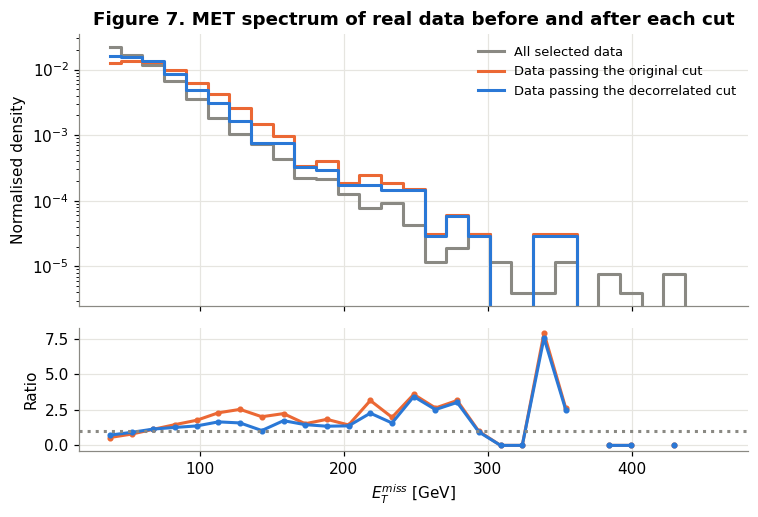

Data events: 17,115; passing original cut: 12.6%; passing decorrelated cut: 13.2%


In [14]:
thr_d_orig = thr_orig; thr_d_dc = thr_dc         # same thresholds as in simulation
bins = np.linspace(30, MET_MAX, 30); ctr = 0.5 * (bins[1:] + bins[:-1])
h_all, _ = np.histogram(data.met, bins=bins, density=True)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7, 4.8), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})
a1.step(ctr, h_all, where='mid', color='#8a8983', label='All selected data')
for col, thr, c, name in (('score', thr_d_orig, COL['orig'], 'original'), ('score_dc', thr_d_dc, COL['dc'], 'decorrelated')):
    h, _ = np.histogram(data.met[data[col] > thr], bins=bins, density=True)
    a1.step(ctr, h, where='mid', color=c, label=f'Data passing the {name} cut')
    with np.errstate(divide='ignore', invalid='ignore'):
        a2.plot(ctr, np.where(h_all > 0, h / h_all, np.nan), color=c, marker='o', ms=3)
a1.set_yscale('log'); a1.set_ylabel('Normalised density'); a1.legend(frameon=False, fontsize=8.5)
a1.set_title('Figure 7. MET spectrum of real data before and after each cut')
a2.axhline(1, color='#8a8983', ls=':'); a2.set_ylabel('Ratio'); a2.set_xlabel('$E_T^{miss}$ [GeV]')
plt.tight_layout(); plt.show()
print(f'Data events: {len(data):,}; passing original cut: {(data.score > thr_d_orig).mean():.1%}; '
      f'passing decorrelated cut: {(data.score_dc > thr_d_dc).mean():.1%}')

## 9. Towards a monojet selection

A true monojet analysis requires **zero leptons**, which no skim in this release provides. It can be done with the unskimmed (`noskim`) files: real data in [record 93933](https://opendata.cern.ch/record/93933) (1.2 TiB) and simulation in [record 93911](https://opendata.cern.ch/record/93911). The changes would be:

1. Set `SKIM = 'noskim'` and read the branches `trigMET`, `lep_n`, `met`, `jet_pt`, `jet_eta`, `jet_phi`, `jet_jvt`, `met_phi`.
2. Select: missing-energy trigger fired, `lep_n == 0`, $E_T^{\text{miss}} > 250$ GeV, leading jet $p_T > 250$ GeV and $|\eta| < 2.4$, at most four jets, and $\Delta\phi$(jet, $E_T^{\text{miss}}$) $> 0.4$ for all jets.
3. Backgrounds: Z($\to\nu\nu$) + jets (dataset numbers 700335 to 700337 in the official examples), W + jets (700338 to 700349) and $t\bar t$ (410470).
4. Signal: check with `atom.match_metadata('physics_short', ...)` or the ATLAS Open Data metadata whether a dark-matter monojet sample exists in this release.

Because the unskimmed files are large, start with a small fraction of one data file.

## 10. Limitations and references

**Limitations**
- Only $t\bar t$ and W + jets are simulated; other processes in data are ignored, so the data comparison in Section 8 is qualitative.
- The physics task ($t\bar t$ versus W + jets, with W + jets as the "background") is chosen to demonstrate decorrelation, not to reproduce an ATLAS measurement.
- Absolute values of event weights are used for training, efficiencies and the decorrelation map. Sherpa W + jets samples contain a fraction of negative weights (reported in Section 3); using signed weights would be more exact but can make weighted percentiles non-monotone.
- Only a subset of events is read by default, and the dataset numbers come from official ATLAS Open Data example notebooks; check the printed short names in Section 2.
- No systematic uncertainties are included.
- The finite-sample reference in Section 7 is a pointwise-in-group comparison, not a formal certificate that holds after fitting the map; constructing such a certificate is the open problem.

**References**
- ATLAS Collaboration (2025). ROOT ntuple format 2015–2016 proton–proton Open Data for Education and Outreach (beta release). CERN Open Data Portal. doi:10.7483/OPENDATA.ATLAS.B5M9.44TN
- P. Chakravarti, L. Kania, O. Behnke, M. Kuusela and L. Wasserman. Robust semi-parametric signal detection in particle physics with classifiers decorrelated via optimal transport. arXiv:2409.06399.
- M. Algren, J. A. Raine and T. Golling. Decorrelation using optimal transport. European Physical Journal C 84, 579 (2024).
- ATLAS Open Data example notebooks: github.com/atlas-outreach-data-tools/notebooks-collection-opendata